<a href="https://colab.research.google.com/github/dhanushnshetty123-dev/Digit-recognizer/blob/main/Digit_recognizer.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Using device: cpu

Starting training...
Epoch 1/3 - Loss: 0.1419
Epoch 2/3 - Loss: 0.0421
Epoch 3/3 - Loss: 0.0287

Test Accuracy: 98.81%


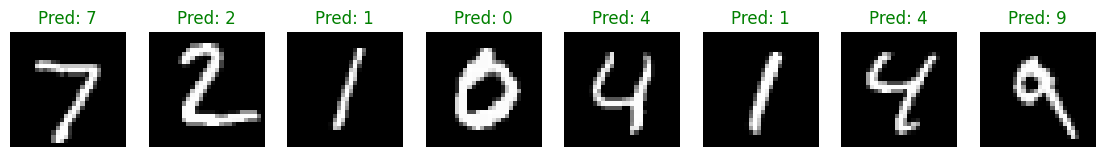

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt

# 1. Setup Device (Uses Colab GPU automatically if enabled)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# 2. Load & Normalize the MNIST Dataset
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

train_dataset = datasets.MNIST(root='./data', train=True, download=True, transform=transform)
test_dataset = datasets.MNIST(root='./data', train=False, download=True, transform=transform)

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=1000, shuffle=False)

# 3. Define a Simple Convolutional Neural Network (CNN)
class DigitRecognizer(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )
        self.fc = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 7 * 7, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        return self.fc(self.conv(x))

model = DigitRecognizer().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

# 4. Train the Model (3 Epochs)
print("\nStarting training...")
for epoch in range(1, 4):
    model.train()
    total_loss = 0
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()

    print(f"Epoch {epoch}/3 - Loss: {total_loss/len(train_loader):.4f}")

# 5. Evaluate Accuracy on Test Data
model.eval()
correct = 0
with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        preds = outputs.argmax(dim=1)
        correct += (preds == labels).sum().item()

accuracy = 100 * correct / len(test_dataset)
print(f"\nTest Accuracy: {accuracy:.2f}%")

# 6. Visualize 8 Sample Predictions
images, labels = next(iter(test_loader))
with torch.no_grad():
    preds = model(images[:8].to(device)).argmax(dim=1).cpu()

fig, axes = plt.subplots(1, 8, figsize=(14, 2))
for i, ax in enumerate(axes):
    ax.imshow(images[i].squeeze(), cmap='gray')
    color = "green" if preds[i] == labels[i] else "red"
    ax.set_title(f"Pred: {preds[i].item()}", color=color)
    ax.axis('off')
plt.show()

In [ ]:
from IPython.display import display, HTML, JSON
from google.colab import output
import base64, io
import numpy as np
from PIL import Image
from scipy import ndimage

def classify(data_url):
    # 1. Decode the canvas image sent from the browser
    img_bytes = base64.b64decode(data_url.split(",")[1])
    img = Image.open(io.BytesIO(img_bytes)).convert("L")

    # 2. Crop to the drawn digit (like MNIST, digits fill a 20x20 box)
    bbox = img.getbbox()
    if bbox is None:
        return JSON({"digit": None, "probs": [0] * 10})
    img = img.crop(bbox)
    w, h = img.size
    scale = 20.0 / max(w, h)
    img = img.resize((max(1, int(w * scale)), max(1, int(h * scale))), Image.LANCZOS)

    # 3. Paste into a 28x28 black canvas
    canvas28 = Image.new("L", (28, 28), 0)
    canvas28.paste(img, ((28 - img.size[0]) // 2, (28 - img.size[1]) // 2))

    # 4. Center by center of mass (how MNIST was prepared)
    arr = np.array(canvas28, dtype=np.float32)
    cy, cx = ndimage.center_of_mass(arr)
    arr = ndimage.shift(arr, (14 - cy, 14 - cx), order=1)

    # 5. Same normalization as training
    x = torch.tensor(arr / 255.0).unsqueeze(0).unsqueeze(0)
    x = ((x - 0.1307) / 0.3081).to(device)

    # 6. Predict
    model.eval()
    with torch.no_grad():
        probs = torch.softmax(model(x), dim=1)[0].cpu().tolist()

    return JSON({"digit": int(np.argmax(probs)), "probs": probs})

output.register_callback("classify", classify)

display(HTML("""
<div style="font-family:sans-serif">
  <canvas id="pad" width="280" height="280"
    style="border:2px solid #888; background:black; touch-action:none; cursor:crosshair"></canvas>
  <div style="margin-top:8px">
    <button id="predictBtn" style="font-size:16px; padding:6px 14px">Predict</button>
    <button id="clearBtn" style="font-size:16px; padding:6px 14px">Clear</button>
  </div>
  <h2 id="result" style="margin:10px 0 0 0">Draw a digit (0-9)</h2>
  <pre id="probs" style="margin:4px 0 0 0"></pre>
</div>
<script>
  const c = document.getElementById('pad');
  const ctx = c.getContext('2d');
  ctx.fillStyle = 'black'; ctx.fillRect(0, 0, 280, 280);
  ctx.strokeStyle = 'white'; ctx.lineWidth = 20; ctx.lineCap = 'round'; ctx.lineJoin = 'round';

  let drawing = false;
  function pos(e) {
    const r = c.getBoundingClientRect();
    return [(e.clientX - r.left) * (c.width / r.width), (e.clientY - r.top) * (c.height / r.height)];
  }
  c.addEventListener('pointerdown', e => { drawing = true; const [x, y] = pos(e); ctx.beginPath(); ctx.moveTo(x, y); ctx.lineTo(x + 0.1, y); ctx.stroke(); });
  c.addEventListener('pointermove', e => { if (!drawing) return; const [x, y] = pos(e); ctx.lineTo(x, y); ctx.stroke(); });
  window.addEventListener('pointerup', () => { drawing = false; });

  document.getElementById('clearBtn').onclick = () => {
    ctx.fillStyle = 'black'; ctx.fillRect(0, 0, 280, 280);
    document.getElementById('result').innerText = 'Draw a digit (0-9)';
    document.getElementById('probs').innerText = '';
  };

  document.getElementById('predictBtn').onclick = async () => {
    const res = await google.colab.kernel.invokeFunction('classify', [c.toDataURL('image/png')], {});
    const out = res.data['application/json'];
    if (out.digit === null) { document.getElementById('result').innerText = 'Draw something first!'; return; }
    document.getElementById('result').innerText = 'Prediction: ' + out.digit +
      '  (' + (out.probs[out.digit] * 100).toFixed(1) + '% sure)';
    document.getElementById('probs').innerText = out.probs
      .map((p, i) => i + ': ' + '█'.repeat(Math.round(p * 20)) + ' ' + (p * 100).toFixed(1) + '%').join('\\n');
  };
</script>
"""))